# Benchmarking Metacloning Methods on In Silico Simulated Data

This notebook benchmarks **ChronoClone** against 6 other clustering and metacloning workflows on pre-generated simulated data (12 ground-truth metaclones, ODE-based differentiation).

We compare the following methods:
1. **ChronoClone** (Consensus co-clustering + threshold sweep on normalized trajectories)
2. **CLADES** (Leiden clustering on raw cell counts using PCA and k-NN graph)
3. **CLADES on Normalized Input** (Leiden clustering on ChronoClone's normalized trajectories using PCA and k-NN graph)
4. **k-Means on CLADES Raw Counts** (k-Means with 12 clusters on raw cell counts)
5. **k-Means on Normalized Input** (k-Means with 12 clusters on normalized trajectories)
6. **Hierarchical Clustering on CLADES Raw Counts** (Agglomerative clustering with 12 clusters on raw cell counts)
7. **Hierarchical Clustering on Normalized Input** (Agglomerative clustering with 12 clusters on normalized trajectories)

We measure the recovery accuracy vs the ground-truth metaclone labels using the **Adjusted Rand Index (ARI)** (where 1.0 represents perfect recovery of the original metaclones).

## 0. Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from chronoclone import (
    build_clone_table,
    normalize_clone_table,
    run_chronoclone_validation,
    run_clades_validation,
    run_clades_norm_validation,
    run_kmeans_raw_validation,
    run_kmeans_norm_validation,
    run_hierarchical_raw_validation,
    run_hierarchical_norm_validation,
)

np.random.seed(42)
sns.set_theme(style='whitegrid')

## 1. Constants

In [2]:
time = ['0', '4', '9', '15']
days = [0, 4, 9, 15]
pop  = ['HSC', 'HSPC', 'MEP', 'CMP', 'Mk_prog', 'MEMP',
        'GMP', 'GMDP', 'Mast_prog', 'Baso_prog', 'Neu_prog', 'DC_prog', 'Mono_prog']
vec = ['Day' + j + '_Cluster' + i for i in pop for j in time]
DAYS_CTRL    = ['Day0', 'Day4', 'Day9', 'Day15']
DATA_DIR     = 'simulated_data/Standard'

## 2. Load Simulated Data

In [3]:
df = []
for j in range(1, 13):
    temp = pd.read_csv(
        os.path.join(DATA_DIR, f'simulated_clones_meta{j}.csv'),
        header=None
    )
    temp.index = 'c' + temp.index.astype(str) + '_mc' + str(j)
    df.append(temp)

final_table = pd.concat(df)
final_table.columns = vec

# Per-timepoint totals and overall total
for day in days:
    day_cols = [col for col in final_table.columns if col.startswith(f'Day{day}_')]
    final_table[f'Day_{day}_Total'] = final_table[day_cols].sum(axis=1)

final_table['total_count'] = final_table[[f'Day_{day}_Total' for day in days]].sum(axis=1)

print(f'final_table shape  : {final_table.shape}')
print(f'Clones retained    : {len(final_table)}')

final_table shape  : (517, 57)
Clones retained    : 517


## 3. Run Benchmark Workflows

We calculate the Adjusted Rand Index (ARI) score for each of the 7 workflows.

In [4]:
# Precompute normalized table (used by multiple normalized input methods)
import anndata as ad
cell_rows = []
for clone_id, row in final_table[vec].iterrows():
    for ct in pop:
        for t in time:
            col = f'Day{t}_Cluster{ct}'
            n = int(max(0, round(row[col])))
            for _ in range(n):
                cell_rows.append({
                    'LARRY_ID'  : clone_id,
                    'day'       : t,
                    'cell_type' : ct,
                    'condition' : 'C',
                })

obs = pd.DataFrame(cell_rows)
obs.index = obs.index.astype(str)
adata_ctrl = ad.AnnData(X=np.zeros((len(obs), 1)), obs=obs)

clone_table = build_clone_table(adata_ctrl, 'LARRY_ID', 'day', 'cell_type', time, pop)
norm_table = normalize_clone_table(clone_table, DAYS_CTRL, pop)

# Run each method
print("Running ChronoClone...")
ari_chronoclone = run_chronoclone_validation(final_table, min_cells=3)

print("Running CLADES (Raw Counts)...")
ari_clades = run_clades_validation(final_table, min_cells=3, resolution=1.0, n_neighbors=15)

print("Running CLADES (Normalized Input)...")
ari_clades_norm = run_clades_norm_validation(final_table, norm_table, min_cells=3, resolution=1.0, n_neighbors=15)

print("Running k-Means (Raw Counts)...")
ari_kmeans_raw = run_kmeans_raw_validation(final_table, min_cells=3, n_clusters=12)

print("Running k-Means (Normalized Input)...")
ari_kmeans_norm = run_kmeans_norm_validation(final_table, norm_table, min_cells=3, n_clusters=12)

print("Running Hierarchical (Raw Counts)...")
ari_agg_raw = run_hierarchical_raw_validation(final_table, min_cells=3, n_clusters=12)

print("Running Hierarchical (Normalized Input)...")
ari_agg_norm = run_hierarchical_norm_validation(final_table, norm_table, min_cells=3, n_clusters=12)

print("Done!")

Running ChronoClone...


2026-06-26 19:06:59.424378: I tensorflow/core/util/port.cc:110] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-06-26 19:07:20.251195: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-06-26 19:08:44.000968: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


Starting threshold sweep...

Selected threshold : 0.55
Max silhouette score: 0.461
Clusters            : 12
Running CLADES (Raw Counts)...


/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/sklearn/manifold/_spectral_embedding.py:273: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Running CLADES (Normalized Input)...


/path/to/hpc-work/LIBS/mamba/envs/LARRY_env/lib/python3.8/site-packages/sklearn/manifold/_spectral_embedding.py:273: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


Running k-Means (Raw Counts)...
Running k-Means (Normalized Input)...
Running Hierarchical (Raw Counts)...
Running Hierarchical (Normalized Input)...
Done!


## 4. Summary & Comparison

,Method,Adjusted Rand Index (ARI)
0,ChronoClone,1.000000
1,CLADES (Raw Counts),0.730430
2,CLADES (Normalized Input),0.730430
5,Hierarchical (Raw Counts),0.670702
6,Hierarchical (Normalized Input),0.670702
4,k-Means (Normalized Input),0.666582
3,k-Means (Raw Counts),0.660959


/tmp/ipykernel_704082/667212167.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x='Method', y='Adjusted Rand Index (ARI)', palette=colors)


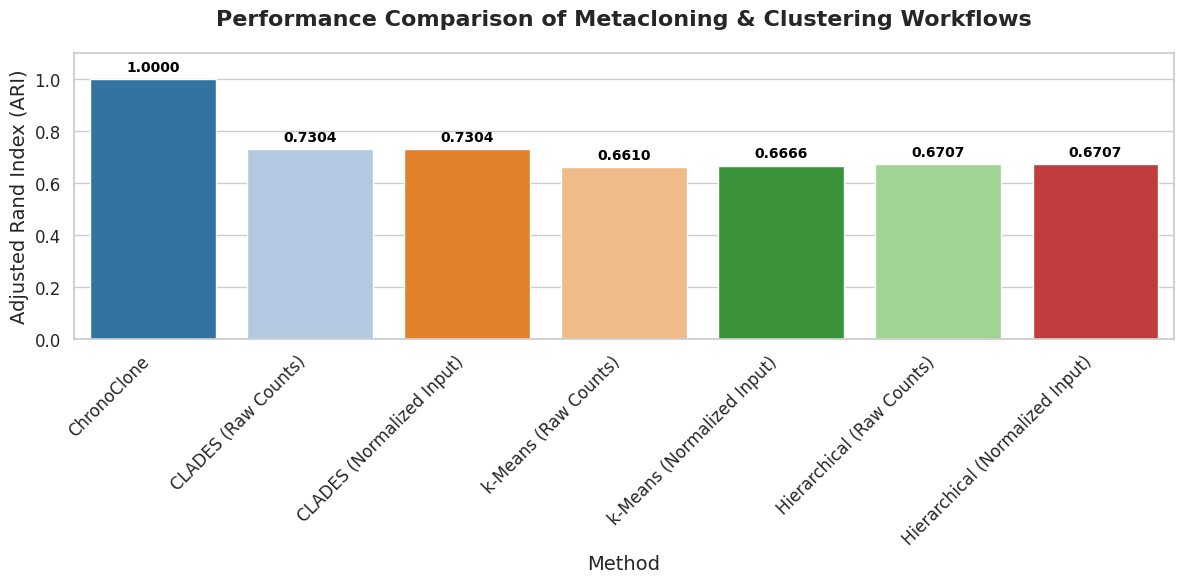

In [5]:
# Compile results
results_df = pd.DataFrame({
    'Method': [
        'ChronoClone',
        'CLADES (Raw Counts)',
        'CLADES (Normalized Input)',
        'k-Means (Raw Counts)',
        'k-Means (Normalized Input)',
        'Hierarchical (Raw Counts)',
        'Hierarchical (Normalized Input)'
    ],
    'Adjusted Rand Index (ARI)': [
        ari_chronoclone,
        ari_clades,
        ari_clades_norm,
        ari_kmeans_raw,
        ari_kmeans_norm,
        ari_agg_raw,
        ari_agg_norm
    ]
})

display(results_df.sort_values(by='Adjusted Rand Index (ARI)', ascending=False).style.bar(subset=['Adjusted Rand Index (ARI)'], color='#5f9ea0'))
results_df.to_csv('simulated_data/benchmarking_insillico_results.csv', index=False)

# Plot comparison
plt.figure(figsize=(12, 6))
colors = ['#1f77b4', '#aec7e8', '#ff7f0e', '#ffbb78', '#2ca02c', '#98df8a', '#d62728']
sns.barplot(data=results_df, x='Method', y='Adjusted Rand Index (ARI)', palette=colors)
plt.ylim(0, 1.1)
plt.ylabel('Adjusted Rand Index (ARI)', fontsize=14)
plt.xlabel('Method', fontsize=14)
plt.title('Performance Comparison of Metacloning & Clustering Workflows', fontsize=16, fontweight='bold', pad=20)
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)

for index, row in results_df.iterrows():
    plt.text(index, row['Adjusted Rand Index (ARI)'] + 0.02, f"{row['Adjusted Rand Index (ARI)']:.4f}", 
             color='black', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('simulated_data/benchmarking_insillico_comparison_plot.png', dpi=300)
plt.show()